Overlaping 
Question 2

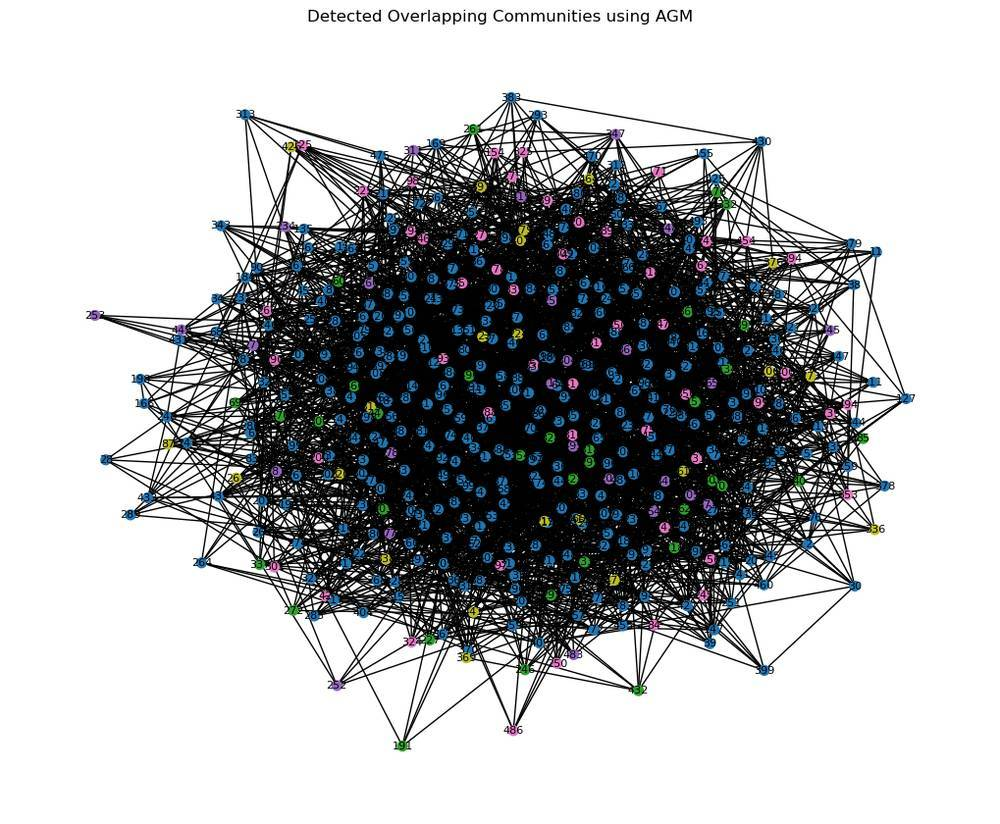

In [9]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
import numpy as np

data = pd.read_csv('F:/Aidin/Universities/Amirkabir (Master)/Lessons/Term 2/Analysis of Complex Networks/Assignments/HW2/Answer/Dataset/Overlaping/overlaping_dataset.csv')
G = nx.Graph()
G.add_edges_from(data.values)

def initialize_agm(G, num_communities):
    membership = {node: np.random.rand(num_communities) for node in G.nodes()}
    membership = {node: membership[node] / membership[node].sum() for node in G.nodes()}  
    Pc = np.random.rand(num_communities)
    return membership, Pc

def compute_likelihood(G, membership, Pc):
    likelihood = 0
    for u, v in G.edges():
        edge_prob = 1 - np.prod(1 - np.outer(membership[u], membership[v]) * Pc)
        likelihood += np.log(edge_prob + 1e-10)
    return likelihood

def optimize_agm(G, membership, Pc, num_iterations=50, learning_rate=0.01):
    for _ in range(num_iterations):
        for u, v in G.edges():
            delta = np.outer(membership[u], membership[v]) * Pc
            edge_prob = 1 - np.prod(1 - delta)
            grad_membership_u = (1 / (edge_prob + 1e-10)) * delta * (1 - delta)
            grad_membership_v = grad_membership_u.T
            membership[u] += learning_rate * grad_membership_u.sum(axis=1)
            membership[v] += learning_rate * grad_membership_v.sum(axis=0)
        # Normalizing membership
        for node in membership:
            membership[node] /= membership[node].sum()
        # Updatting Pc
        for c in range(len(Pc)):
            Pc[c] += learning_rate * sum(
                membership[u][c] * membership[v][c] for u, v in G.edges()
            )

    return membership, Pc

num_communities = 5
membership, Pc = initialize_agm(G, num_communities)
membership, Pc = optimize_agm(G, membership, Pc)
# Visualizing the communities
color_map = {}
for node in G.nodes():
    top_community = np.argmax(membership[node])
    color_map[node] = plt.cm.tab10(top_community / num_communities)

colors = [color_map[node] for node in G.nodes()]
plt.figure(figsize=(10, 8))
nx.draw(G, node_color=colors, with_labels=True, node_size=50, font_size=8)
plt.title('Detected Overlapping Communities using AGM')
plt.show()

C:\Users\TamirLand\AppData\Roaming\Python\Python39\site-packages\numpy\core\numeric.py:925: RuntimeWarning: overflow encountered in multiply
  return multiply(a.ravel()[:, newaxis], b.ravel()[newaxis, :], out)
C:\Users\TamirLand\AppData\Local\Temp\ipykernel_8328\1692771843.py:35: RuntimeWarning: invalid value encountered in multiply
  grad_membership_u = (1 / (edge_prob + 1e-10)) * delta * (1 - delta)


Number of communities: 1, Likelihood: nan


C:\Users\TamirLand\AppData\Local\Temp\ipykernel_8328\1692771843.py:26: RuntimeWarning: invalid value encountered in log
  likelihood += np.log(edge_prob + 1e-10)


Number of communities: 2, Likelihood: nan
Number of communities: 3, Likelihood: nan
Number of communities: 4, Likelihood: nan
Number of communities: 5, Likelihood: nan
Number of communities: 6, Likelihood: 3.400000281147445e-07
Number of communities: 7, Likelihood: 3.400000281147445e-07
Number of communities: 8, Likelihood: 3.3999776325977427e-07
Number of communities: 9, Likelihood: 3.0079236877700974e-07
Number of communities: 10, Likelihood: -1.4940842635055735e-05
Number of communities: 11, Likelihood: -0.000526191731823442
Number of communities: 12, Likelihood: -0.007200589219172906
Number of communities: 13, Likelihood: -0.06174839006398852
Number of communities: 14, Likelihood: -0.24332543199082637
Number of communities: 15, Likelihood: -0.8681746566861875
Number of communities: 16, Likelihood: -2.160050848324086
Number of communities: 17, Likelihood: -4.537382051203776
Number of communities: 18, Likelihood: -9.632141994940001
Number of communities: 19, Likelihood: -16.946193610

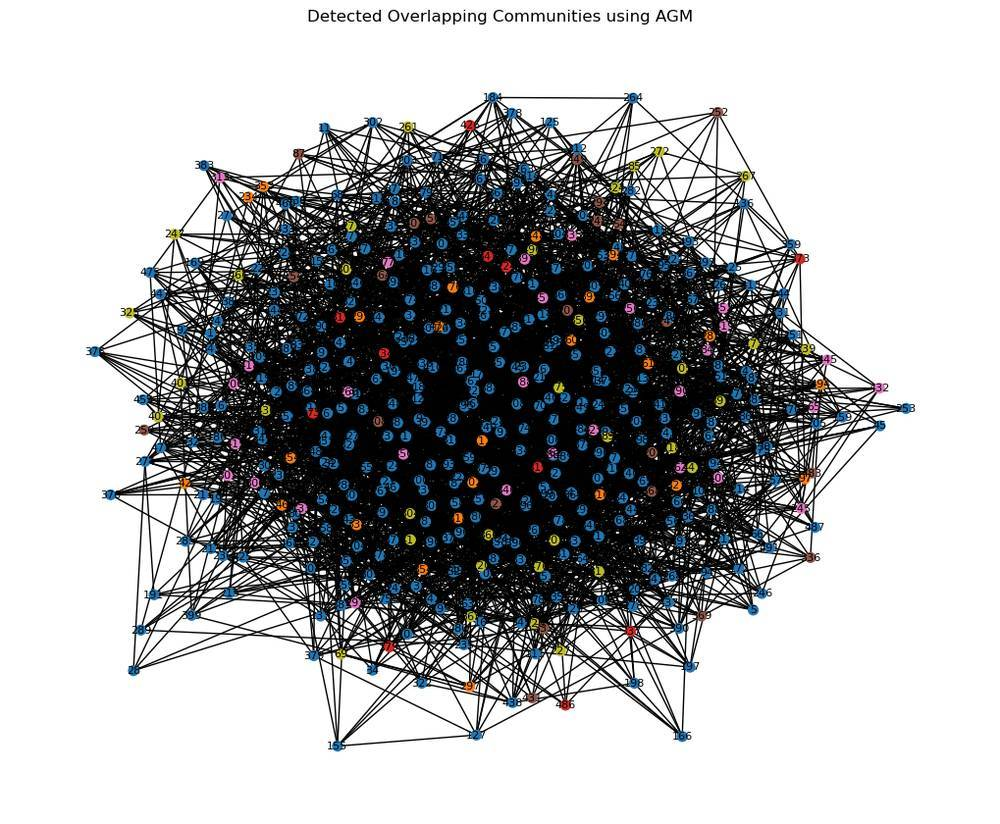

In [7]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
import numpy as np

data = pd.read_csv('F:/Aidin/Universities/Amirkabir (Master)/Lessons/Term 2/Analysis of Complex Networks/Assignments/HW2/Answer/Dataset/Overlaping/overlaping_dataset.csv')
G = nx.Graph()
G.add_edges_from(data.values)

def initialize_agm(G, num_communities):
    membership = {node: np.random.rand(num_communities) for node in G.nodes()}
    membership = {node: membership[node] / membership[node].sum() for node in G.nodes()} 
    return membership, Pc

def compute_likelihood(G, membership, Pc):
    likelihood = 0
    for u, v in G.edges():
        edge_prob = 1 - np.prod(1 - np.outer(membership[u], membership[v]) * Pc)
        likelihood += np.log(edge_prob + 1e-10)
    return likelihood

def optimize_agm(G, membership, Pc, num_iterations=50, learning_rate=0.01):
    for _ in range(num_iterations):
        for u, v in G.edges():
            delta = np.outer(membership[u], membership[v]) * Pc
            edge_prob = 1 - np.prod(1 - delta)
            grad_membership_u = (1 / (edge_prob + 1e-10)) * delta * (1 - delta)
            grad_membership_v = grad_membership_u.T
            membership[u] += learning_rate * grad_membership_u.sum(axis=1)
            membership[v] += learning_rate * grad_membership_v.sum(axis=0)
        # Normalizing membership
        for node in membership:
            membership[node] /= membership[node].sum()
        # Update Pc
        for c in range(len(Pc)):
            Pc[c] += learning_rate * sum(
                membership[u][c] * membership[v][c] for u, v in G.edges()
            )
    return membership, Pc

def find_optimal_communities(G, max_communities):
    best_num_communities = 1
    best_likelihood = float('-inf')
    for k in range(1, max_communities + 1):
        membership, Pc = initialize_agm(G, k)
        membership, Pc = optimize_agm(G, membership, Pc)
        likelihood = compute_likelihood(G, membership, Pc)
        print(f"Number of communities: {k}, Likelihood: {likelihood}")
        if likelihood > best_likelihood:
            best_likelihood = likelihood
            best_num_communities = k
    return best_num_communities

max_communities = 20
optimal_num_communities = find_optimal_communities(G, max_communities)
print(f"Optimal number of communities: {optimal_num_communities}")
membership, Pc = initialize_agm(G, optimal_num_communities)
membership, Pc = optimize_agm(G, membership, Pc)
# Visualizingthe top 4 community structures
color_map = {}
for node in G.nodes():
    top_community = np.argmax(membership[node])
    color_map[node] = plt.cm.tab10(top_community / optimal_num_communities)

colors = [color_map[node] for node in G.nodes()]
plt.figure(figsize=(10, 8))
nx.draw(G, node_color=colors, with_labels=True, node_size=50, font_size=8)
plt.title('Detected Overlapping Communities using AGM')
plt.show()

C:\Users\TamirLand\AppData\Roaming\Python\Python39\site-packages\numpy\core\numeric.py:925: RuntimeWarning: overflow encountered in multiply
  return multiply(a.ravel()[:, newaxis], b.ravel()[newaxis, :], out)
C:\Users\TamirLand\AppData\Local\Temp\ipykernel_8328\2853139114.py:35: RuntimeWarning: invalid value encountered in multiply
  grad_membership_u = (1 / (edge_prob + 1e-10)) * delta * (1 - delta)
C:\Users\TamirLand\AppData\Local\Temp\ipykernel_8328\2853139114.py:26: RuntimeWarning: invalid value encountered in log
  likelihood += np.log(edge_prob + 1e-10)


Number of communities: 6, Likelihood: 3.400000281147445e-07
Number of communities: 7, Likelihood: 3.400000281147445e-07
Number of communities: 8, Likelihood: 3.39998518211431e-07
Number of communities: 9, Likelihood: 2.960693912128367e-07
Number of communities: 10, Likelihood: -1.5823846771641843e-05
Number of communities: 11, Likelihood: -0.0006581612404331725
Number of communities: 12, Likelihood: -0.009466571957525203
Number of communities: 13, Likelihood: -0.0560449446787494
Number of communities: 14, Likelihood: -0.28260206494172435
Number of communities: 15, Likelihood: -0.8652959010910227
Number of communities: 16, Likelihood: -2.3069951615040893
Number of communities: 17, Likelihood: -4.996641725372093
Number of communities: 18, Likelihood: -8.791623675078302
Number of communities: 19, Likelihood: -15.562737601187251
Number of communities: 20, Likelihood: -24.210702232096935
Top communities by likelihood:
Rank 1: 6 communities with likelihood 3.400000281147445e-07
Rank 2: 7 com

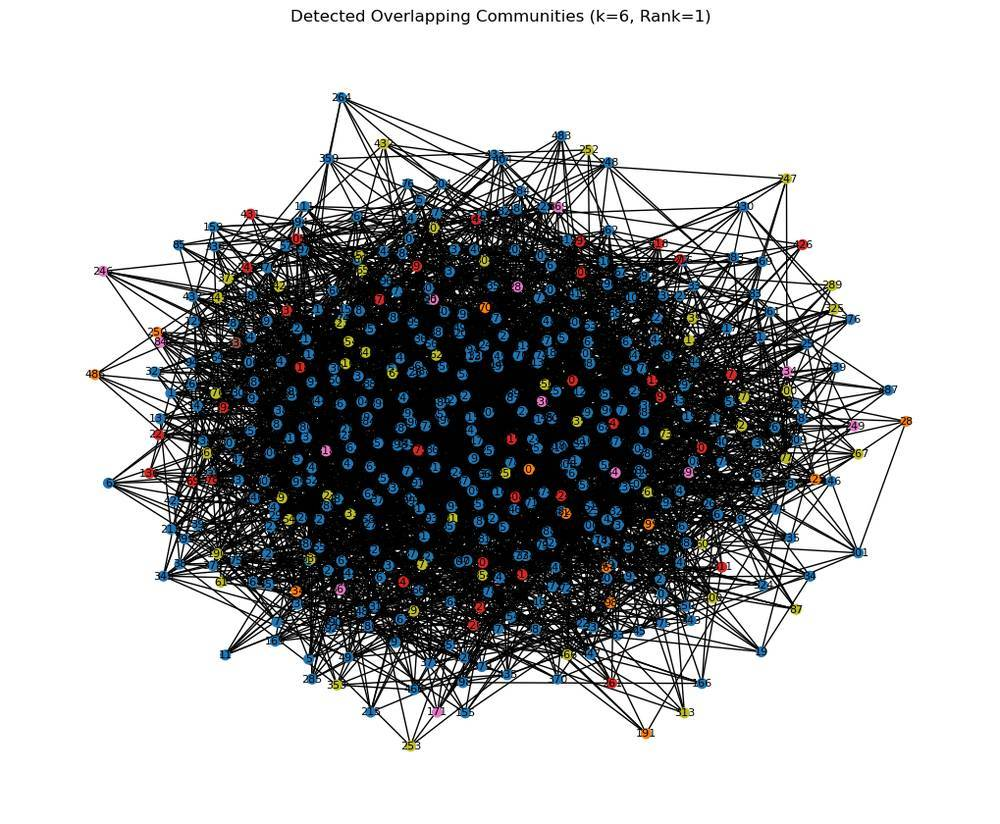

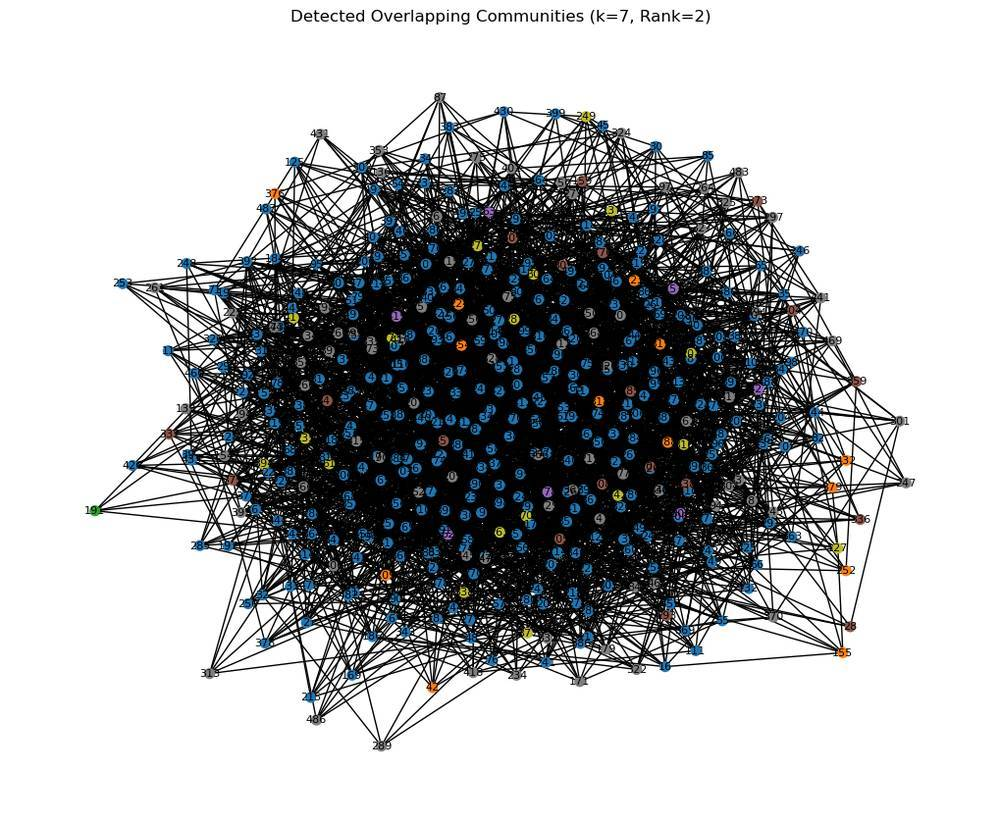

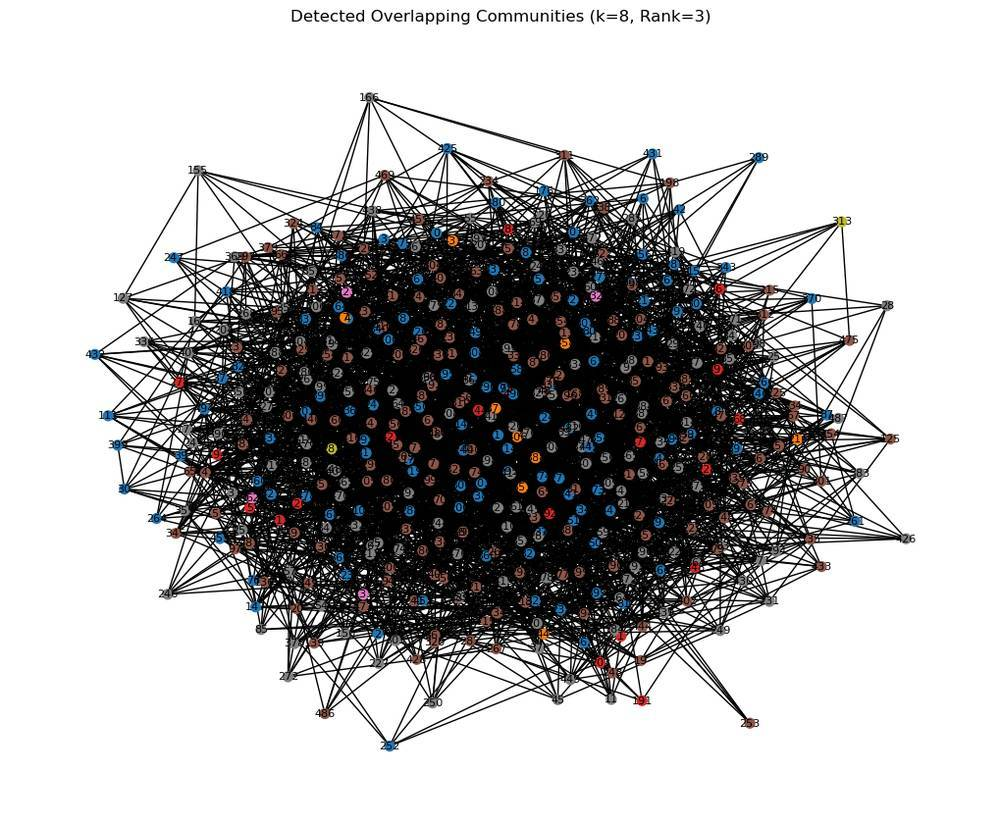

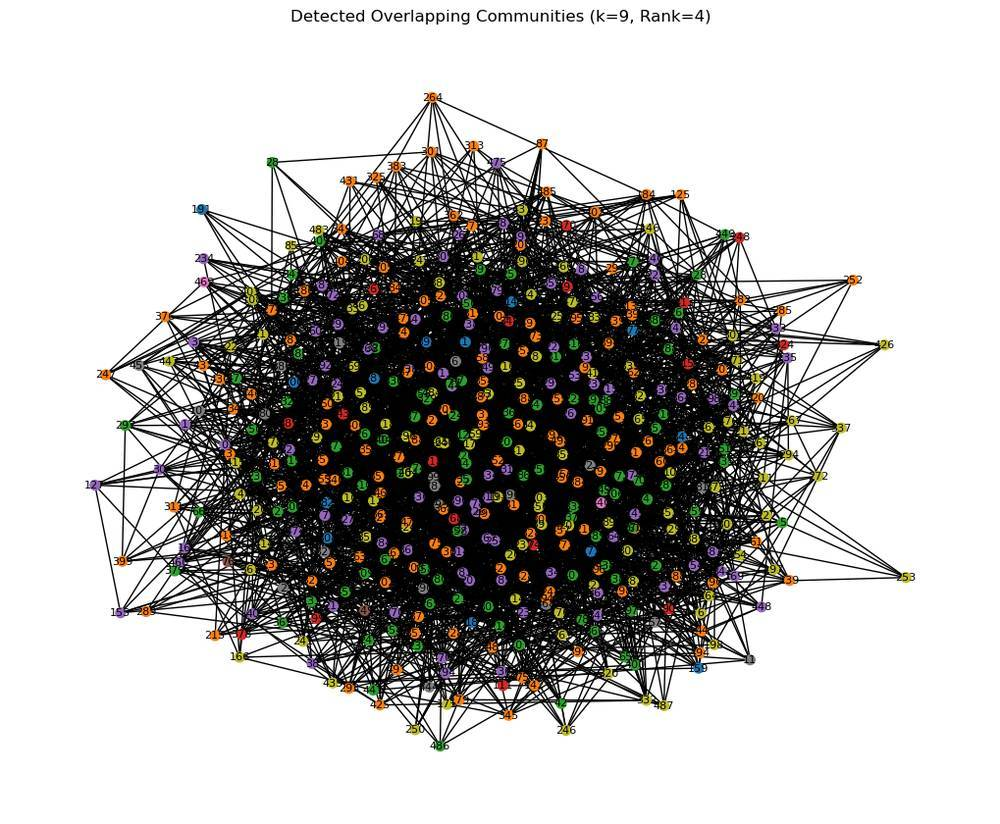

In [11]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
import numpy as np

data = pd.read_csv('F:/Aidin/Universities/Amirkabir (Master)/Lessons/Term 2/Analysis of Complex Networks/Assignments/HW2/Answer/Dataset/Overlaping/overlaping_dataset.csv')
G = nx.Graph()
G.add_edges_from(data.values)
def initialize_agm(G, num_communities):
    membership = {node: np.random.rand(num_communities) for node in G.nodes()}
    membership = {node: membership[node] / membership[node].sum() for node in G.nodes()}
    Pc = np.random.rand(num_communities)
    return membership, Pc

def compute_likelihood(G, membership, Pc):
    likelihood = 0
    for u, v in G.edges():
        edge_prob = 1 - np.prod(1 - np.outer(membership[u], membership[v]) * Pc)
        likelihood += np.log(edge_prob + 1e-10)
    return likelihood

def optimize_agm(G, membership, Pc, num_iterations=50, learning_rate=0.01):
    for _ in range(num_iterations):
        for u, v in G.edges():
            delta = np.outer(membership[u], membership[v]) * Pc
            edge_prob = 1 - np.prod(1 - delta)
            grad_membership_u = (1 / (edge_prob + 1e-10)) * delta * (1 - delta)
            grad_membership_v = grad_membership_u.T
            membership[u] += learning_rate * grad_membership_u.sum(axis=1)
            membership[v] += learning_rate * grad_membership_v.sum(axis=0)
        # Normalization of membership
        for node in membership:
            membership[node] /= membership[node].sum()
        # Updatting Pc
        for c in range(len(Pc)):
            Pc[c] += learning_rate * sum(
                membership[u][c] * membership[v][c] for u, v in G.edges()
            )
    return membership, Pc

def find_top_communities(G, max_communities, top_n=4):
    community_results = []
    for k in range(1, max_communities + 1):
        membership, Pc = initialize_agm(G, k)
        membership, Pc = optimize_agm(G, membership, Pc)
        likelihood = compute_likelihood(G, membership, Pc)
        if not np.isnan(likelihood):
            community_results.append((k, likelihood, membership, Pc))
            print(f"Number of communities: {k}, Likelihood: {likelihood}")
    community_results.sort(key=lambda x: x[1], reverse=True)
    return community_results[:top_n]

max_communities = 20
valid_communities = find_top_communities(G, max_communities)
print("Top communities by likelihood:")
for rank, (k, likelihood, _, _) in enumerate(valid_communities, 1):
    print(f"Rank {rank}: {k} communities with likelihood {likelihood}")
for rank, (k, likelihood, membership, Pc) in enumerate(valid_communities, 1):
    color_map = {}
    for node in G.nodes():
        top_community = np.argmax(membership[node])
        color_map[node] = plt.cm.tab10(top_community / k)
    colors = [color_map[node] for node in G.nodes()]
    plt.figure(figsize=(10, 8))
    nx.draw(G, node_color=colors, with_labels=True, node_size=50, font_size=8)
    plt.title(f'Detected Overlapping Communities (k={k}, Rank={rank})')
    plt.show()